# 03 · Dois algoritmos disputam o modelo preditivo

Passo **6 do fluxo único**. Dois algoritmos distintos são treinados sobre as **mesmas features eleitas** e o **mesmo conjunto de treino**, com o **mesmo protocolo de avaliação**:

* **Modelo A – Random Forest** (bagging de árvores independentes, tamanho limitado por `max_leaf_nodes`);
* **Modelo B – XGBoost** (boosting por gradiente: árvores sequenciais que corrigem o erro das anteriores).

Hiperparâmetros e a opção de balanceamento de classes vêm do `config.yaml` e são registrados no MLflow.

Protocolo: StratifiedKFold (k do `config.yaml`, mesma semente) no treino. Em cada fold, o pré-processamento é ajustado no treino do fold e as features são as eleitas **naquele fold** (notebook 02) — idênticas para A e B. Em seguida, cada algoritmo é re-treinado no treino completo com as features eleitas do ciclo. Hiperparâmetros, sementes, métricas, features e artefatos dos dois runs vão para o MLflow com o mesmo `cycle_id`.

In [1]:
import sys
from pathlib import Path

# Caminhos consistentes: localiza a raiz do projeto (pasta com config/config.yaml)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(RAIZ))
from src.config import preparar_notebook

cfg = preparar_notebook()  # muda o diretório de trabalho para a raiz do projeto

import json

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 4)})

import sklearn
import xgboost

from src import ciclo, modelagem, monitoramento, rastreamento
from src import preprocessamento as pp
from src.config import RAIZ, ler_json, relativo, salvar_json

ctx = ciclo.carregar_ciclo(exigir=["01_etl", "02_votacao"])
EVID = ciclo.dir_evidencias(ctx)
DIR_PROC = Path(cfg["dados"]["dir_processed"])
votacao = ler_json(EVID / "votacao_features.json")
assert votacao["cycle_id"] == ctx["cycle_id"], "votação de outro ciclo"
eleitas = votacao["eleitas"]
features_por_fold = {int(f): v for f, v in votacao["eleitas_por_fold"].items()}
print(f"cycle_id = {ctx['cycle_id']} | data_version = {ctx['data_version']} | {len(eleitas)} features eleitas")

cycle_id = c0004-20261122T170836Z | data_version = dv004-e76b61ae | 30 features eleitas


In [2]:
base = pd.read_parquet(DIR_PROC / "base_features.parquet")
treino = base[base["particao"] == "treino"].reset_index(drop=True)
X_treino = treino[pp.COLUNAS_FEATURES]
classes = cfg["dados"]["classes"]
y_treino = modelagem.codificar_alvo(treino["type"], classes)
folds = np.load(DIR_PROC / "folds_treino.npy")
assert len(folds) == len(X_treino)

especs = {"modelo_a": cfg["modelos"]["modelo_a"], "modelo_b": cfg["modelos"]["modelo_b"]}
assert especs["modelo_a"]["algoritmo"] != especs["modelo_b"]["algoritmo"], "os dois modelos devem ser algoritmos distintos"
display(pd.DataFrame({p: {"algoritmo": e["algoritmo"], **e["params"]} for p, e in especs.items()}).T)

,algoritmo,n_estimators,max_leaf_nodes,min_samples_leaf,max_features,max_depth,learning_rate,subsample,colsample_bytree
modelo_a,random_forest,100,256,2,sqrt,NaN,NaN,NaN,NaN
modelo_b,xgboost,200,NaN,NaN,NaN,6,0.15,0.8,0.8


## Validação cruzada com protocolo idêntico

,papel,algoritmo,fold,n_treino,n_validacao,n_features,f1_macro,accuracy,balanced_accuracy,recall_macro,log_loss,tempo_treino_s
0,modelo_a,random_forest,0,25119,6280,31,0.7317,0.7188,0.7718,0.7718,0.6465,1.17
1,modelo_b,xgboost,0,25119,6280,31,0.7575,0.7645,0.7992,0.7992,0.5173,1.68
2,modelo_a,random_forest,1,25119,6280,29,0.7242,0.7139,0.7747,0.7747,0.6560,1.13
3,modelo_b,xgboost,1,25119,6280,29,0.7587,0.7669,0.8038,0.8038,0.5231,1.72
4,modelo_a,random_forest,2,25119,6280,31,0.7335,0.7231,0.7775,0.7775,0.6539,1.12
5,modelo_b,xgboost,2,25119,6280,31,0.7642,0.7667,0.7977,0.7977,0.5224,1.69
6,modelo_a,random_forest,3,25119,6280,29,0.7400,0.7202,0.7812,0.7812,0.6460,1.13
7,modelo_b,xgboost,3,25119,6280,29,0.7567,0.7578,0.7967,0.7967,0.5252,1.66
8,modelo_a,random_forest,4,25120,6279,31,0.7418,0.7234,0.7830,0.7830,0.6482,1.13
9,modelo_b,xgboost,4,25120,6279,31,0.7634,0.7624,0.8027,0.8027,0.5126,1.71


f1_macro         accuracy         balanced_accuracy         recall_macro         log_loss         tempo_treino_s        
                           mean     std     mean     std              mean     std         mean     std     mean     std           mean     std
papel    algoritmo                                                                                                                             
modelo_a random_forest   0.7342  0.0070   0.7199  0.0039            0.7777  0.0046       0.7777  0.0046   0.6501  0.0046          1.136  0.0195
modelo_b xgboost         0.7601  0.0035   0.7637  0.0038            0.8000  0.0031       0.8000  0.0031   0.5201  0.0051          1.692  0.0239

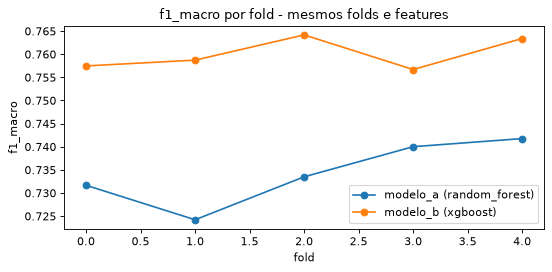

In [3]:
cv = modelagem.validacao_cruzada(X_treino, y_treino, folds, features_por_fold, especs, cfg)
metrica = cfg["avaliacao"]["metrica_principal"]
cols = ["f1_macro", "accuracy", "balanced_accuracy", "recall_macro", "log_loss", "tempo_treino_s"]
display(cv[["papel", "algoritmo", "fold", "n_treino", "n_validacao", "n_features", *cols]].round(4))
resumo_cv = cv.groupby(["papel", "algoritmo"])[cols].agg(["mean", "std"]).round(4)
display(resumo_cv)

fig, ax = plt.subplots(figsize=(7, 3.5))
for papel, grupo in cv.groupby("papel"):
    ax.plot(grupo["fold"], grupo[metrica], marker="o", label=f"{papel} ({grupo['algoritmo'].iloc[0]})")
ax.set_xlabel("fold"); ax.set_ylabel(metrica); ax.set_title(f"{metrica} por fold - mesmos folds e features"); ax.legend()
fig.tight_layout(); fig.savefig(EVID / "treino_cv_por_fold.png"); plt.show()

## Treino final dos dois candidatos e registro no MLflow

Cada candidato é serializado como um pipeline único (pré-processamento + seleção das features eleitas + estimador), registrado no MLflow (`mlflow.sklearn.log_model`, com o código de `src/` embutido) e também como *bundle* `joblib` que inclui o perfil de referência usado pelo monitoramento de drift.

In [4]:
semente = cfg["avaliacao"]["semente"]
pip_req = [f"scikit-learn=={sklearn.__version__}", f"xgboost=={xgboost.__version__}", f"pandas=={pd.__version__}", f"numpy=={np.__version__}"]
perfil = monitoramento.perfil_referencia(X_treino, cfg["monitoramento"]["bins"])
cv.to_csv(EVID / "treino_cv_folds.csv", index=False)
candidatos = {}
(DIR_PROC / "candidatos").mkdir(parents=True, exist_ok=True)

for papel, spec in especs.items():
    pipe = modelagem.construir_pipeline(cfg, eleitas, spec, semente)
    modelagem.ajustar(pipe, X_treino, y_treino, spec, cfg)
    proba_treino = pipe.predict_proba(X_treino)
    m_treino = modelagem.calcular_metricas(y_treino, proba_treino, classes)
    metadados = {"algoritmo": spec["algoritmo"], "papel": papel, "cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"],
                 "params": spec["params"], "semente": semente, "n_treino": len(X_treino)}
    bundle = modelagem.ModeloURL(pipe, classes, eleitas, metadados, perfil_referencia=perfil)
    arq_bundle = DIR_PROC / "candidatos" / f"{papel}.joblib"
    joblib.dump(bundle, arq_bundle, compress=3)
    m_cv = cv[cv["papel"] == papel]
    with rastreamento.run_etapa(ctx, cfg, f"03_{papel}_{spec['algoritmo']}", "03_treino", tags={"papel": papel, "algoritmo": spec["algoritmo"]}) as run:
        mlflow.log_params({"papel": papel, "algoritmo": spec["algoritmo"], "semente": semente, "cv_folds": cfg["avaliacao"]["cv_folds"],
                           "balancear_classes": cfg["modelos"]["balancear_classes"], "n_features": len(eleitas),
                           "features": ",".join(eleitas), **{f"hp_{k}": v for k, v in spec["params"].items()}})
        for r in m_cv.itertuples():
            mlflow.log_metric(f"cv_{metrica}_fold", getattr(r, metrica), step=int(r.fold))
        mlflow.log_metrics({f"cv_{c}_media": m_cv[c].mean() for c in cols} | {f"cv_{c}_desvio": m_cv[c].std() for c in cols})
        mlflow.log_metrics({f"treino_{k}": v for k, v in m_treino.items() if k in ("f1_macro", "accuracy")})
        mlflow.log_dict({"features": eleitas, "features_por_fold": features_por_fold}, "features.json")
        mlflow.log_artifact(str(EVID / "treino_cv_folds.csv"))
        info = mlflow.sklearn.log_model(pipe, name="modelo", serialization_format="cloudpickle", code_paths=[str(RAIZ / "src")],
                                        input_example=X_treino.head(3), pip_requirements=pip_req)
        candidatos[papel] = {"run_id": run.info.run_id, "model_uri": info.model_uri, "algoritmo": spec["algoritmo"],
                             "features": eleitas, "arquivo_bundle": relativo(arq_bundle),
                             "cv_media": float(m_cv[metrica].mean()), "cv_desvio": float(m_cv[metrica].std())}
    print(f"{papel} ({spec['algoritmo']}): CV {metrica} = {m_cv[metrica].mean():.4f} ± {m_cv[metrica].std():.4f} | run_id={run.info.run_id}")

salvar_json({"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"], "metrica": metrica, "candidatos": candidatos},
            EVID / "treino_candidatos.json")

2026/11/22 17:19:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run c0004-20261122T170836Z/03_modelo_a_random_forest at: http://127.0.0.1:5000/#/experiments/1/runs/80f6a765029d4587afbe3995640985d0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
modelo_a (random_forest): CV f1_macro = 0.7342 ± 0.0070 | run_id=80f6a765029d4587afbe3995640985d0


2026/11/22 17:19:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run c0004-20261122T170836Z/03_modelo_b_xgboost at: http://127.0.0.1:5000/#/experiments/1/runs/146a3be28eb34d08b59da8f36638a4eb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
modelo_b (xgboost): CV f1_macro = 0.7601 ± 0.0035 | run_id=146a3be28eb34d08b59da8f36638a4eb


PosixPath('/home/runner/work/n3_cybersecurity/n3_cybersecurity/evidencias/c0004-20261122T170836Z/treino_candidatos.json')

In [5]:
ctx = ciclo.registrar_etapa(ctx, "03_treino", run_ids={p: c["run_id"] for p, c in candidatos.items()},
                            algoritmos={p: c["algoritmo"] for p, c in candidatos.items()})
print("Etapa 03 concluída: dois candidatos treinados e registrados com o mesmo cycle_id.")

Etapa 03 concluída: dois candidatos treinados e registrados com o mesmo cycle_id.
